[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/04_gradients_backprop.ipynb)

# 04 · Gradients & Backpropagation from Zero

**Part 0 — Foundations** · Notebook 4 of 27

Notebook 03 showed that training means repeatedly stepping against the gradient. But a neural network can have billions of parameters. How do we get the derivative of the loss with respect to **every one of them**, cheaply, at every step?

The answer is **backpropagation**: the chain rule from calculus, applied systematically to a graph of simple operations. In this notebook we build it ourselves, in the spirit of Andrej Karpathy's *micrograd*:

1. What a derivative is, measured numerically
2. Partial derivatives and the gradient
3. The chain rule, worked by hand
4. A tiny **autograd engine** (`Value`) that records every operation as a graph and runs the chain rule backward through it
5. Neurons, layers and a multi-layer perceptron built **only** from our engine
6. Training that network to classify a 2-D dataset, and watching the decision boundary form
7. Checking our gradients against numerical estimates and against **PyTorch**
8. From scalars to matrices: vectorized backprop in NumPy
9. Classic bugs and the vanishing-gradient problem

By the end, `loss.backward()` in PyTorch will no longer be magic: you'll have written it.

*Course map: CX 4240 Lecture 11 (Neural Networks: Backpropagation); ISYE 4600 W10 (Neural Networks) and HW4 (backpropagation derivation).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import math, random, time
try:
    import graphviz                      # for drawing computation graphs (preinstalled in Colab)
except ImportError:
    %pip install -q graphviz
    import graphviz

Setup complete ✓


---
## 1. Why we need gradients, and three ways to get them

To run gradient descent we need $\nabla_\theta L$, the derivative of the loss with respect to every parameter. There are three ways to compute it:

| Method | How | Cost for $P$ parameters | Problem |
|---|---|---|---|
| **Numerical** | nudge each parameter, re-run the model, see how the loss changes | $\approx 2P$ forward passes | hopelessly slow for big models; approximate |
| **Symbolic** | derive one big formula by hand or with algebra software | — | formulas blow up in size; impossible for 100-layer networks |
| **Automatic (reverse mode) = backprop** | record the operations, apply the chain rule backward | $\approx$ **one** forward + **one** backward pass | none (this is what PyTorch does) |

The last row is the magic: the gradient of a function with a billion inputs costs about the same as evaluating the function once or twice. Let's build up to it.

---
## 2. What is a derivative, really?

The derivative tells you: **if I nudge the input a tiny bit, how much does the output respond, per unit of nudge?**

$$f'(x) = \lim_{h\to 0}\frac{f(x+h) - f(x)}{h}$$

Let's measure it with a concrete function, $f(x) = 3x^2 - 4x + 5$ (whose derivative, by the power rule, is $6x - 4$).

In [2]:
def f(x):
    return 3 * x**2 - 4 * x + 5

x = 3.0
for h in [1.0, 0.1, 0.001, 0.00001]:
    slope = (f(x + h) - f(x)) / h
    print(f"h = {h:<8}  (f(x+h) − f(x)) / h = {slope:.6f}")
print(f"exact derivative 6x − 4 at x = 3: {6*x - 4}")

h = 1.0       (f(x+h) − f(x)) / h = 17.000000
h = 0.1       (f(x+h) − f(x)) / h = 14.300000
h = 0.001     (f(x+h) − f(x)) / h = 14.003000
h = 1e-05     (f(x+h) − f(x)) / h = 14.000030
exact derivative 6x − 4 at x = 3: 14.0


🎚️ **Drag $x$ and $h$.** The orange line through $x$ and $x+h$ (a "secant") approaches the true tangent line (dashed) as $h \to 0$. Where the slope is negative, nudging $x$ up makes $f$ go down; at $x = 2/3$ the slope is zero (the minimum).

In [3]:
def plot_derivative(x=3.0, h=1.0):
    xx = np.linspace(-2, 4, 300)
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot(xx, f(xx), color=C["blue"], label="f(x) = 3x² − 4x + 5")
    secant = (f(x + h) - f(x)) / h
    ax.plot(xx, f(x) + secant * (xx - x), color=C["orange"], label=f"secant slope = {secant:.3f}")
    ax.plot(xx, f(x) + (6 * x - 4) * (xx - x), color=C["ink"], ls="--", lw=1.2, label=f"true slope = {6*x-4:.3f}")
    ax.plot([x, x + h], [f(x), f(x + h)], "o", color=C["orange"], ms=8)
    ax.set(ylim=(-5, 40), xlim=(-2, 4), xlabel="x"); ax.legend(loc="upper left"); plt.show()

interact(plot_derivative, x=FloatSlider(value=3, min=-1.5, max=3.5, step=0.05, description="x"),
         h=FloatSlider(value=1, min=0.01, max=2, step=0.01, description="h"));

> 🤔 **Question: So why not just use a really tiny $h$, like $10^{-15}$?**
>
> Because computers store numbers with about 16 significant digits. With a tiny $h$, $f(x+h)$ and $f(x)$ agree in almost all their digits, and subtracting them leaves mostly rounding noise ("catastrophic cancellation"). There's a sweet spot. The **central difference** $\frac{f(x+h) - f(x-h)}{2h}$ is far more accurate, which is why we'll use it for gradient checking later.

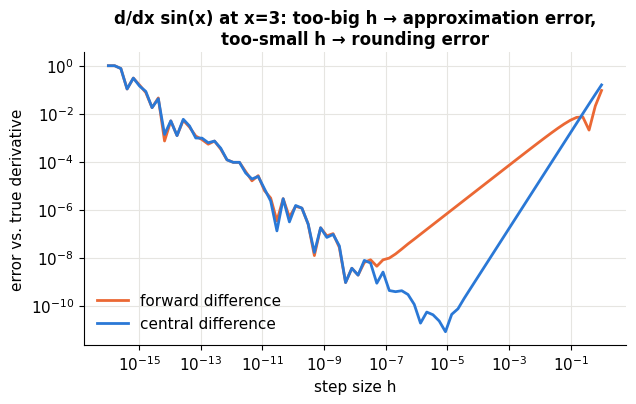

In [4]:
# Use sin(x) here (true derivative cos(x)): for a quadratic, the central difference happens to be exact.
hs = np.logspace(-16, 0, 80)
fwd = np.abs((np.sin(3 + hs) - np.sin(3)) / hs - np.cos(3))
ctr = np.abs((np.sin(3 + hs) - np.sin(3 - hs)) / (2 * hs) - np.cos(3))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(hs, fwd + 1e-17, color=C["orange"], label="forward difference")
ax.loglog(hs, ctr + 1e-17, color=C["blue"], label="central difference")
ax.set(xlabel="step size h", ylabel="error vs. true derivative", title="d/dx sin(x) at x=3: too-big h → approximation error,\ntoo-small h → rounding error")
ax.legend(); plt.show()

---
## 3. Many inputs: partial derivatives

Most functions have many inputs. A **partial derivative** asks how the output responds to nudging **one** input while holding the others fixed. Take

$$d = a \cdot b + c$$

with $a = 2$, $b = -3$, $c = 10$, so $d = 4$. Nudge each input by $h$:

In [5]:
a, b, c = 2.0, -3.0, 10.0
h = 1e-4
d0 = a * b + c
print(f"d = {d0}")
print(f"∂d/∂a ≈ {((a + h) * b + c - d0) / h:.4f}   (calculus says: b = {b})")
print(f"∂d/∂b ≈ {(a * (b + h) + c - d0) / h:.4f}   (calculus says: a = {a})")
print(f"∂d/∂c ≈ {(a * b + (c + h) - d0) / h:.4f}   (calculus says: 1)")

d = 4.0
∂d/∂a ≈ -3.0000   (calculus says: b = -3.0)
∂d/∂b ≈ 2.0000   (calculus says: a = 2.0)
∂d/∂c ≈ 1.0000   (calculus says: 1)


Notice the rules: for **multiplication**, the derivative with respect to one input is **the other input**. For **addition**, it's just **1**. Keep these two in mind; they're most of backprop.

Stack all the partial derivatives into a vector and you get the **gradient** $\nabla f$, which (notebook 03) points in the direction of steepest increase, perpendicular to the contour lines:

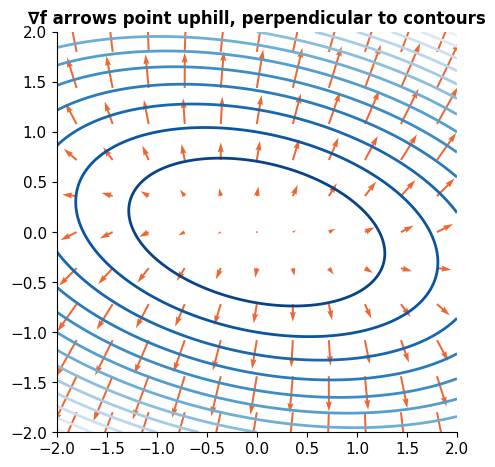

In [6]:
g2 = lambda X, Y: X**2 + 3 * Y**2 + X * Y
gx = lambda X, Y: 2 * X + Y
gy = lambda X, Y: 6 * Y + X
xs = np.linspace(-2, 2, 200); X, Y = np.meshgrid(xs, xs)
q = np.linspace(-1.8, 1.8, 11); QX, QY = np.meshgrid(q, q)
fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.contour(X, Y, g2(X, Y), levels=15, cmap="Blues_r")
ax.quiver(QX, QY, gx(QX, QY), gy(QX, QY), color=C["orange"], angles="xy", scale=90, width=0.005)
ax.set(aspect="equal", title="∇f arrows point uphill, perpendicular to contours"); ax.grid(False); plt.show()

---
## 4. The chain rule

Most interesting functions are **compositions**: the output of one operation feeds into the next. If $z$ depends on $y$ and $y$ depends on $x$, then

$$\frac{dz}{dx} = \frac{dz}{dy}\cdot\frac{dy}{dx}$$

Intuition (from George Simmons' calculus book): *"If a car travels twice as fast as a bicycle and the bicycle is four times as fast as a walking man, then the car travels 2 × 4 = 8 times as fast as the man."* Rates of change **multiply** along a chain.

### Worked example by hand

$$L = (a\cdot b + c)\cdot f, \qquad a=2,\; b=-3,\; c=10,\; f=-2$$

Break it into single operations, compute **forward**:

$$e = a\cdot b = -6, \qquad d = e + c = 4, \qquad L = d\cdot f = -8$$

Now go **backward**, from $L$ to the inputs, using only the two local rules (multiply: "the other input"; add: "1") and the chain rule:

| Variable | Gradient $\partial L/\partial(\cdot)$ | Why |
|---|---|---|
| $L$ | $1$ | base case |
| $f$ | $d = 4$ | $L = d\cdot f$: the other input |
| $d$ | $f = -2$ | the other input |
| $c$ | $\frac{\partial L}{\partial d}\cdot 1 = -2$ | addition passes the gradient through unchanged |
| $e$ | $\frac{\partial L}{\partial d}\cdot 1 = -2$ | same |
| $a$ | $\frac{\partial L}{\partial e}\cdot b = -2 \cdot -3 = 6$ | chain rule × the other input |
| $b$ | $\frac{\partial L}{\partial e}\cdot a = -2 \cdot 2 = -4$ | chain rule × the other input |

That's backpropagation. Every node only needs to know (1) the gradient arriving from above and (2) its own **local** derivative. Let's check numerically:

In [7]:
def L_fn(a, b, c, f):
    return (a * b + c) * f

vals = dict(a=2.0, b=-3.0, c=10.0, f=-2.0)
base = L_fn(**vals)
for k in vals:
    nudged = dict(vals); nudged[k] += 1e-6
    print(f"∂L/∂{k} ≈ {(L_fn(**nudged) - base) / 1e-6:+.4f}")

∂L/∂a ≈ +6.0000
∂L/∂b ≈ -4.0000
∂L/∂c ≈ -2.0000
∂L/∂f ≈ +4.0000


> 🤔 **Question: Why go backward? Couldn't we push derivatives forward from the inputs?**
>
> You can ("forward-mode" autodiff), but forward mode computes the derivative with respect to **one input** per pass. Backward ("reverse mode") computes the derivative of **one output** with respect to **all inputs** in one pass. In ML we always have one output (the scalar loss) and millions of inputs (the parameters), so backward wins by a factor of millions.

---
## 5. Building an autograd engine: the `Value` class

Now we automate this. A `Value` wraps a single number and remembers **how it was made**: which `Value`s were its inputs (`_prev`) and which operation produced it (`_op`). Doing math with `Value`s therefore silently builds a **computation graph**.

**Step 1: just the forward pass and the graph.**

In [8]:
class Value:
    """A scalar that remembers the operations that produced it (forward pass only, for now)."""
    def __init__(self, data, _children=(), _op="", label=""):
        self.data = data
        self.grad = 0.0                 # ∂(final output)/∂(this value); 0 until backprop runs
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value({self.label}: data={self.data:.4f}, grad={self.grad:.4f})"

    def __add__(self, other):
        return Value(self.data + other.data, (self, other), "+")

    def __mul__(self, other):
        return Value(self.data * other.data, (self, other), "×")

a = Value(2.0, label="a"); b = Value(-3.0, label="b"); c = Value(10.0, label="c"); f = Value(-2.0, label="f")
e = a * b;  e.label = "e"
d = e + c;  d.label = "d"
L = d * f;  L.label = "L"
print(L)
print("L was produced by", repr(L._op), "from", L._prev)

Value(L: data=-8.0000, grad=0.0000)
L was produced by '×' from {Value(d: data=4.0000, grad=0.0000), Value(f: data=-2.0000, grad=0.0000)}


Let's draw the graph. Each box shows a value's **data** and its **grad** (still 0); the round nodes are operations.

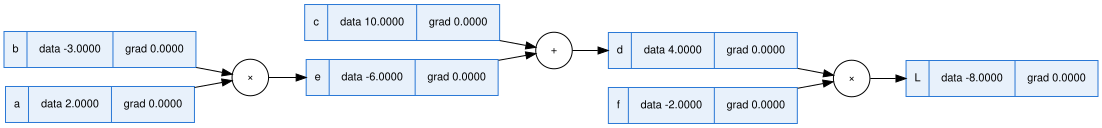

In [9]:
def trace(root):
    """Collect all nodes and edges in the graph that produced `root`."""
    nodes, edges, stack = set(), set(), [root]
    while stack:
        v = stack.pop()
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v)); stack.append(child)
    return nodes, edges

def draw_dot(root):
    nodes, edges = trace(root)
    dot = graphviz.Digraph(graph_attr={"rankdir": "LR"}, node_attr={"fontname": "Helvetica", "fontsize": "11"})
    for n in nodes:
        uid = str(id(n))
        dot.node(uid, label=f"{{ {n.label} | data {n.data:.4f} | grad {n.grad:.4f} }}", shape="record",
                 style="filled", fillcolor="#e8f1fb" if n.grad == 0 else "#fde3d6", color=C["blue"])
        if n._op:
            dot.node(uid + n._op, label=n._op, shape="circle", width="0.3", style="filled", fillcolor="#ffffff")
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

draw_dot(L)

**Step 2: backprop by hand, on the real graph.** Fill in the gradients exactly as in the table above, then redraw. The boxes turn orange once they have a gradient.

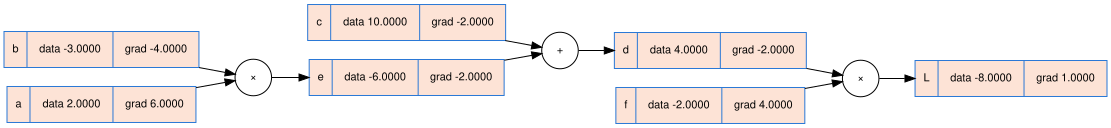

In [10]:
L.grad = 1.0
f.grad = d.data * L.grad          # × node: the other input
d.grad = f.data * L.grad
c.grad = 1.0 * d.grad             # + node: pass it through
e.grad = 1.0 * d.grad
a.grad = b.data * e.grad          # × node: the other input, times the gradient from above
b.grad = a.data * e.grad
draw_dot(L)

### Step 3: automate it

Notice each node did the **same local job**: take the gradient arriving at its output (`out.grad`), multiply by its local derivative, and **add** it into each input's `.grad`. So we give every operation a little `_backward` function that does exactly that, then call them all in the right order: from the output back to the inputs, making sure each node runs only after every node that uses it has finished (a **reverse topological order**).

Here's the full engine. Every operation is a forward computation plus its local derivative:

| Operation | Forward | Local derivative(s) |
|---|---|---|
| $a + b$ | `a.data + b.data` | 1, 1 |
| $a \times b$ | `a.data * b.data` | `b.data`, `a.data` |
| $a^k$ | `a.data**k` | $k\,a^{k-1}$ |
| $e^a$ | `exp(a.data)` | $e^a$ (the output itself) |
| $\tanh(a)$ | `tanh(a.data)` | $1 - \tanh^2(a)$ |
| $\text{ReLU}(a)$ | `max(0, a.data)` | 1 if $a > 0$ else 0 |

In [11]:
class Value:
    """A scalar value with automatic differentiation (a tiny version of PyTorch's autograd)."""
    def __init__(self, data, _children=(), _op="", label=""):
        self.data = float(data)
        self.grad = 0.0
        self._backward = lambda: None           # how to push my gradient into my inputs
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

    # ---- operations: each defines forward AND its local backward rule ----
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "×")
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, k):
        assert isinstance(k, (int, float)), "only constant powers are supported"
        out = Value(self.data ** k, (self,), f"^{k}")
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        out = Value(math.exp(self.data), (self,), "exp")
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(max(0.0, self.data), (self,), "ReLU")
        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward
        return out

    # ---- conveniences built from the operations above ----
    def __neg__(self):            return self * -1
    def __sub__(self, other):     return self + (-other)
    def __truediv__(self, other): return self * (other if isinstance(other, Value) else Value(other)) ** -1
    def __radd__(self, other):    return self + other          # so that 2 + Value works
    def __rmul__(self, other):    return self * other          # so that 2 * Value works
    def __rsub__(self, other):    return Value(other) - self
    def __rtruediv__(self, other): return Value(other) / self

    # ---- the backward pass ----
    def backward(self):
        # 1. topological order: every node appears after all of its inputs
        topo, visited, stack = [], set(), [(self, False)]
        while stack:
            node, processed = stack.pop()
            if processed:
                topo.append(node); continue
            if node in visited:
                continue
            visited.add(node)
            stack.append((node, True))
            for child in node._prev:
                if child not in visited:
                    stack.append((child, False))
        # 2. seed the output and apply the chain rule backward
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

print("Value engine ready ✓")

Value engine ready ✓


Let's re-run the hand example, now with one call to `.backward()`:

{'a': 6.0, 'b': -4.0, 'c': -2.0, 'f': 4.0, 'e': -2.0, 'd': -2.0}


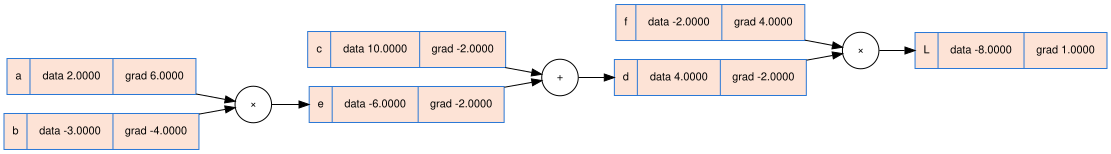

In [12]:
a = Value(2.0, label="a"); b = Value(-3.0, label="b"); c = Value(10.0, label="c"); f = Value(-2.0, label="f")
e = a * b; e.label = "e"
d = e + c; d.label = "d"
L = d * f; L.label = "L"
L.backward()
print({v.label: v.grad for v in [a, b, c, f, e, d]})
draw_dot(L)

Exactly the numbers we computed by hand: $\partial L/\partial a = 6$, $\partial L/\partial b = -4$, and so on.

### A neuron

A single artificial neuron computes a weighted sum of its inputs plus a bias, then squashes it with an activation function:

$$o = \tanh(x_1 w_1 + x_2 w_2 + b)$$

(This example and its numbers follow Karpathy's micrograd lecture; the bias is chosen so the output is a round 0.7071.)

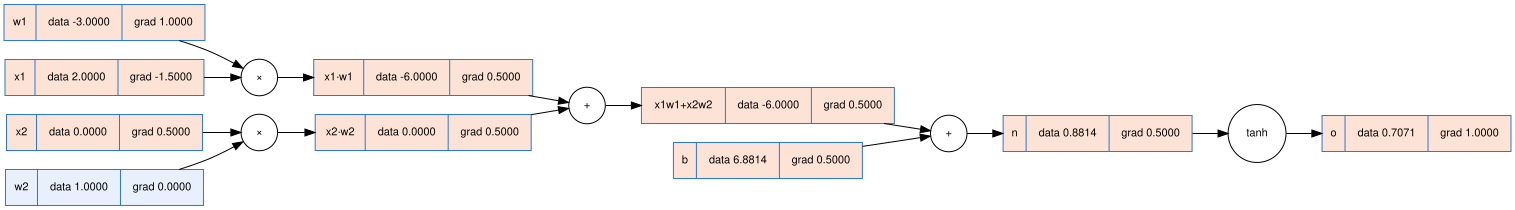

In [13]:
x1 = Value(2.0, label="x1"); x2 = Value(0.0, label="x2")
w1 = Value(-3.0, label="w1"); w2 = Value(1.0, label="w2")
bias = Value(6.8813735870195432, label="b")
x1w1 = x1 * w1; x1w1.label = "x1·w1"
x2w2 = x2 * w2; x2w2.label = "x2·w2"
s = x1w1 + x2w2; s.label = "x1w1+x2w2"
n = s + bias; n.label = "n"
o = n.tanh(); o.label = "o"
o.backward()
draw_dot(o)

Read the gradients:
- $\partial o/\partial n = 1 - \tanh^2(n) = 1 - 0.7071^2 = 0.5$.
- The `+` nodes pass that 0.5 straight through to `b`, `x1·w1` and `x2·w2`.
- $\partial o/\partial w_2 = x_2 \cdot 0.5 = 0$: since $x_2 = 0$, changing $w_2$ has no effect. The gradient correctly says "this weight doesn't matter for this input".
- $\partial o/\partial w_1 = x_1 \cdot 0.5 = 1.0$: increasing $w_1$ would increase the output.

> 🤔 **Question: Why does the engine use `+=` instead of `=` when setting gradients?**
>
> Because a value can be used **more than once**. In `b = a + a`, the gradient reaches `a` along two paths, and the multivariable chain rule says to **add** contributions from all paths. With `=`, the second path would overwrite the first. Here's the bug in action:

In [14]:
class BuggyValue(Value):
    def __add__(self, other):
        out = BuggyValue(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad = out.grad            # BUG: '=' instead of '+='
            other.grad = out.grad
        out._backward = _backward
        return out

for cls in (Value, BuggyValue):
    a = cls(3.0); b = a + a; b.backward()
    print(f"{cls.__name__:10s}: b = a + a,  db/da = {a.grad}   (correct answer: 2)")

Value     : b = a + a,  db/da = 2.0   (correct answer: 2)
BuggyValue: b = a + a,  db/da = 1.0   (correct answer: 2)


### The level of granularity is up to you

We implemented `tanh` as one operation with its own derivative. We could instead build it from smaller pieces, $\tanh(x) = \frac{e^{2x} - 1}{e^{2x} + 1}$, using only `exp`, `+`, `-`, `/`. The graph gets bigger but the gradients are identical, because the chain rule is exact. Frameworks choose "fused" operations for speed, not correctness.

In [15]:
def neuron_output(use_exp_pieces):
    x1, x2, w1, w2 = Value(2.0), Value(0.0), Value(-3.0), Value(1.0)
    b = Value(6.8813735870195432)
    n = x1 * w1 + x2 * w2 + b
    o = ((2 * n).exp() - 1) / ((2 * n).exp() + 1) if use_exp_pieces else n.tanh()
    o.backward()
    return o.data, [round(v.grad, 6) for v in (x1, x2, w1, w2, b)], len(trace(o)[0])

for flag in (False, True):
    out, grads, size = neuron_output(flag)
    print(f"{'exp pieces' if flag else 'fused tanh':10s}: o = {out:.4f}, grads (x1,x2,w1,w2,b) = {grads}, graph nodes = {size}")

fused tanh: o = 0.7071, grads (x1,x2,w1,w2,b) = [-1.5, 0.5, 1.0, 0.0, 0.5], graph nodes = 10
exp pieces: o = 0.7071, grads (x1,x2,w1,w2,b) = [-1.5, 0.5, 1.0, 0.0, 0.5], graph nodes = 21


### Same thing in PyTorch

PyTorch's `autograd` is this engine, but for **tensors** (arrays) instead of scalars, with hundreds of operations implemented in fast C++/CUDA. The API is nearly identical:

In [16]:
import torch
x1 = torch.tensor(2.0, dtype=torch.double, requires_grad=True)
x2 = torch.tensor(0.0, dtype=torch.double, requires_grad=True)
w1 = torch.tensor(-3.0, dtype=torch.double, requires_grad=True)
w2 = torch.tensor(1.0, dtype=torch.double, requires_grad=True)
b = torch.tensor(6.8813735870195432, dtype=torch.double, requires_grad=True)
o = torch.tanh(x1 * w1 + x2 * w2 + b)
o.backward()
print(f"PyTorch: o = {o.item():.4f}")
for name, t in [("x1", x1), ("x2", x2), ("w1", w1), ("w2", w2), ("b", b)]:
    print(f"  ∂o/∂{name} = {t.grad.item():+.4f}")

PyTorch: o = 0.7071
  ∂o/∂x1 = -1.5000
  ∂o/∂x2 = +0.5000
  ∂o/∂w1 = +1.0000
  ∂o/∂w2 = +0.0000
  ∂o/∂b = +0.5000


Identical to our engine. 🎉

---
## 6. A neural network library on top of our engine

Now we stack neurons into **layers** and layers into a **multi-layer perceptron (MLP)**, with an interface that mirrors PyTorch's `nn.Module`. Each `Neuron` holds a list of weight `Value`s and a bias `Value`. Calling it on an input builds the graph for $\text{act}(\sum_i w_i x_i + b)$.

In [17]:
class Module:
    def zero_grad(self):
        for p in self.parameters():
            p.grad = 0.0
    def parameters(self):
        return []

class Neuron(Module):
    def __init__(self, nin, act="tanh"):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(0.0)
        self.act = act
    def __call__(self, x):
        z = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return {"tanh": z.tanh, "relu": z.relu}.get(self.act, lambda: z)()
    def parameters(self):
        return self.w + [self.b]

class Layer(Module):
    def __init__(self, nin, nout, act="tanh"):
        self.neurons = [Neuron(nin, act) for _ in range(nout)]
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP(Module):
    def __init__(self, nin, nouts, act="tanh"):
        sizes = [nin] + nouts
        # hidden layers use the nonlinearity; the final layer is linear
        self.layers = [Layer(sizes[i], sizes[i + 1], act if i < len(nouts) - 1 else "linear") for i in range(len(nouts))]
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

random.seed(42)
model = MLP(3, [4, 4, 1])
print(f"MLP(3 → 4 → 4 → 1) has {len(model.parameters())} parameters")
print("output for input [2, 3, -1]:", model([2.0, 3.0, -1.0]))

MLP(3 → 4 → 4 → 1) has 41 parameters
output for input [2, 3, -1]: Value(data=0.9380, grad=0.0000)


### A first training loop

Four inputs, four desired outputs. The **training loop** is the same four lines in every framework:

1. **forward**: compute predictions and the loss,
2. **zero_grad**: reset gradients from the previous step,
3. **backward**: `loss.backward()`,
4. **update**: nudge every parameter against its gradient.

final predictions: [1.057, -0.989, -1.0, 0.93]  targets: [1.0, -1.0, -1.0, 1.0]


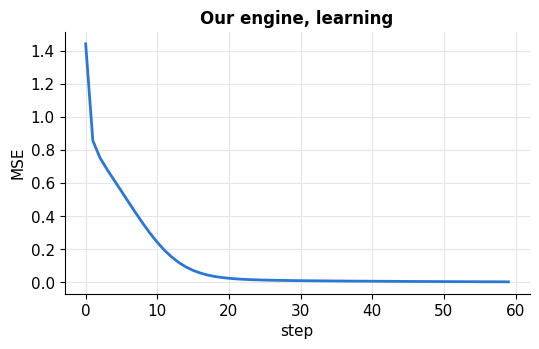

In [18]:
xs = [[2.0, 3.0, -1.0], [3.0, -1.0, 0.5], [0.5, 1.0, 1.0], [1.0, 1.0, -1.0]]
ys = [1.0, -1.0, -1.0, 1.0]

random.seed(42)
model = MLP(3, [4, 4, 1])
history = []
for step in range(60):
    preds = [model(x) for x in xs]                                   # 1. forward
    loss = sum((p - y) ** 2 for p, y in zip(preds, ys)) / len(ys)    #    (mean squared error)
    model.zero_grad()                                                # 2. zero_grad
    loss.backward()                                                  # 3. backward
    for p in model.parameters():                                     # 4. update (gradient descent)
        p.data -= 0.1 * p.grad
    history.append(loss.data)

print("final predictions:", [round(model(x).data, 3) for x in xs], " targets:", ys)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(history, color=C["blue"]); ax.set(xlabel="step", ylabel="MSE", title="Our engine, learning"); plt.show()

---
## 7. Training on a real (2-D) dataset

Now a harder task: classify the two interleaving "moons". The labels are $y \in \{-1, +1\}$ and we use the **hinge loss** $\max(0, 1 - y\cdot\text{score})$ (the SVM loss, notebook 11) plus a little L2 regularization. The network is MLP(2 → 16 → 16 → 1) with ReLU activations: 337 parameters, every one a `Value` in our engine.

This is pure-Python scalar autograd, so each step builds and differentiates a graph of tens of thousands of nodes. It takes 1–2 minutes. (That slowness is exactly why section 8 moves to matrices.)

In [19]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(n_samples=100, noise=0.1, random_state=1)
ym = ym * 2 - 1                                                       # labels -1 / +1

def to_numpy(model):
    """Copy the weights out of the Value objects so we can evaluate the network fast with NumPy."""
    return [(np.array([[w.data for w in nr.w] for nr in layer.neurons]),
             np.array([nr.b.data for nr in layer.neurons]), layer.neurons[0].act) for layer in model.layers]

def np_forward(params, X):
    h = X
    for W, bvec, act in params:
        h = h @ W.T + bvec
        h = np.maximum(h, 0) if act == "relu" else np.tanh(h) if act == "tanh" else h
    return h.ravel()

random.seed(1337)
net = MLP(2, [16, 16, 1], act="relu")
snapshots, losses, accs = [], [], []
t0 = time.time()
for k in range(80):
    scores = [net(list(map(Value, x))) for x in Xm]
    data_loss = sum((1 + -float(yi) * si).relu() for yi, si in zip(ym, scores)) * (1.0 / len(ym))
    reg_loss = 1e-4 * sum(p * p for p in net.parameters())
    loss = data_loss + reg_loss
    acc = np.mean([(si.data > 0) == (yi > 0) for yi, si in zip(ym, scores)])
    net.zero_grad()
    loss.backward()
    lr = 1.0 - 0.9 * k / 80                                           # simple learning-rate decay
    for p in net.parameters():
        p.data -= lr * p.grad
    losses.append(loss.data); accs.append(acc)
    if k % 2 == 0 or k == 79:
        snapshots.append((k, to_numpy(net)))
t_scalar = (time.time() - t0) / 80
print(f"trained in {time.time() - t0:.0f}s ({t_scalar:.2f} s/step) — final loss {losses[-1]:.4f}, accuracy {accs[-1]:.0%}")

trained in 117s (1.47 s/step) — final loss 0.0177, accuracy 100%


### 🎬 Watch the decision boundary form

Left: the network's score over the whole plane (red = predicts +1, blue = predicts −1, black line = the decision boundary) as training proceeds. Right: loss and accuracy.

In [20]:
gx_ = np.linspace(-1.6, 2.6, 160); gy_ = np.linspace(-1.1, 1.6, 120)
GX, GY = np.meshgrid(gx_, gy_); grid = np.column_stack([GX.ravel(), GY.ravel()])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=80, gridspec_kw=dict(width_ratios=[1.3, 1]))
ax2.set(xlim=(0, 80), ylim=(0, max(losses) * 1.05), xlabel="step", title="loss (orange) and accuracy (blue)")
lc, = ax2.plot([], [], color=C["orange"])
ax2b = ax2.twinx(); ax2b.set_ylim(0.4, 1.02); ax2b.grid(False)
ac, = ax2b.plot([], [], color=C["blue"])
fig.tight_layout()

def frame(i):
    k, params = snapshots[i]
    Z = np_forward(params, grid).reshape(GX.shape)
    ax1.cla()
    ax1.contourf(GX, GY, Z, levels=np.linspace(-3, 3, 25), cmap="RdBu_r", extend="both", alpha=0.85)
    ax1.contour(GX, GY, Z, levels=[0], colors=C["ink"], linewidths=2)
    ax1.scatter(*Xm[ym == 1].T, color=C["orange"], edgecolor="white", s=30)
    ax1.scatter(*Xm[ym == -1].T, color=C["blue"], edgecolor="white", marker="s", s=30)
    ax1.set(title=f"step {k}: accuracy {accs[k]:.0%}", xticks=[], yticks=[]); ax1.grid(False)
    lc.set_data(range(k + 1), losses[:k + 1]); ac.set_data(range(k + 1), accs[:k + 1])

show_anim(animation.FuncAnimation(fig, frame, frames=len(snapshots), interval=150))

Every bend in that boundary was learned purely by our ~100-line engine computing gradients with the chain rule.

> 🤔 **Question: Why does the boundary start out as straight-ish pieces and become curvy?**
>
> A ReLU network computes a **piecewise linear** function: each ReLU is a "kink", and the plane gets carved into many linear regions. Early in training the kinks are in random places; training moves and bends them until the zero-contour wraps around the moons. More neurons = more possible kinks = more flexible boundaries. Notebook 19 visualizes the individual regions.

---
## 8. Gradient checking

How do you know a backward pass is correct? Compare it with the numerical central-difference estimate from section 2. The standard measure is the **relative error**

$$\frac{|g_{\text{analytic}} - g_{\text{numeric}}|}{\max(|g_{\text{analytic}}|, |g_{\text{numeric}}|)}$$

and anything around $10^{-7}$ or smaller means the two agree to many digits.

In [21]:
def loss_of(net, X, Y):
    scores = [net(list(map(Value, x))) for x in X]
    return sum((1 + -float(yi) * si).relu() for yi, si in zip(Y, scores)) * (1.0 / len(Y)) + 1e-4 * sum(p * p for p in net.parameters())

random.seed(7)
fresh = MLP(2, [16, 16, 1], act="relu")          # an untrained net, so the gradients are not tiny
Xb, Yb = Xm[:20], ym[:20]
fresh.zero_grad(); L = loss_of(fresh, Xb, Yb); L.backward()
params = fresh.parameters()
check_idx = random.Random(0).sample(range(len(params)), 10)
print(f"{'param':>6} {'backprop':>12} {'numerical':>12} {'rel. error':>11}")
for i in check_idx:
    p = params[i]; old = p.data; h = 1e-5
    p.data = old + h; lp = loss_of(fresh, Xb, Yb).data
    p.data = old - h; lm = loss_of(fresh, Xb, Yb).data
    p.data = old
    num = (lp - lm) / (2 * h)
    rel = abs(p.grad - num) / max(abs(p.grad), abs(num), 1e-12)
    print(f"{i:>6} {p.grad:>12.6f} {num:>12.6f} {rel:>11.1e}")

 param     backprop    numerical  rel. error


   197    -0.172488    -0.172488     1.5e-11
   215    -0.000702    -0.000702     5.7e-09


    20     0.055418     0.055418     7.3e-11


   132     0.000000     0.000000     0.0e+00
   261     0.004934     0.004934     1.5e-10


   248     0.160956     0.160956     2.1e-11


   207     0.004729     0.004729     7.4e-11


   155    -0.000055    -0.000055     1.3e-08
   244    -0.005637    -0.005637     5.8e-10


   183     0.000000     0.000000     0.0e+00


(A few parameters may show a gradient of exactly 0: those belong to ReLU units that are "off" for all 20 examples in this batch, so nudging them changes nothing.)

---
## 9. From scalars to matrices: vectorized backprop

Our engine treats every number as a separate Python object, which is beautiful for learning and terribly slow. Real frameworks apply the **same chain rule to whole arrays at once**. For a 2-layer network on a batch $X \in \mathbb{R}^{n\times d}$:

$$Z_1 = XW_1 + b_1, \quad H = \text{ReLU}(Z_1), \quad \hat y = HW_2 + b_2, \quad L = \tfrac1n\|\hat y - y\|^2$$

The backward pass, one line per forward line, in reverse:

| Gradient | Formula | Shape check |
|---|---|---|
| $\partial L/\partial\hat y$ | $\frac{2}{n}(\hat y - y)$ | $n\times 1$ |
| $\partial L/\partial W_2$ | $H^\top \,\frac{\partial L}{\partial \hat y}$ | $(h \times n)(n \times 1) = h\times 1$ ✓ same as $W_2$ |
| $\partial L/\partial b_2$ | sum of $\frac{\partial L}{\partial\hat y}$ over the batch | $1$ |
| $\partial L/\partial H$ | $\frac{\partial L}{\partial \hat y}\, W_2^\top$ | $(n\times 1)(1 \times h) = n\times h$ ✓ same as $H$ |
| $\partial L/\partial Z_1$ | $\frac{\partial L}{\partial H} \odot \mathbb{1}[Z_1 > 0]$ | $n \times h$ (ReLU passes gradient only where it was "on") |
| $\partial L/\partial W_1$ | $X^\top\, \frac{\partial L}{\partial Z_1}$ | $(d\times n)(n\times h) = d \times h$ ✓ |
| $\partial L/\partial b_1$ | sum of $\frac{\partial L}{\partial Z_1}$ over the batch | $h$ |

**The shape trick**: the gradient with respect to anything always has the same shape as that thing. If you're unsure whether it's $H^\top G$ or $G H^\top$, pick the one whose shapes multiply out correctly. It's almost always the right answer.

### Warm-up: the CX 4240 Lecture 11 network, by hand

Before going to whole batches, let's do the exact example from CX 4240 Lecture 11 on paper, then check it with code. The network has **3 inputs, 2 hidden units and 1 output**, and the loss on one example $(x, y)$ is

$$\ell(x, y, \theta) = \big(f(x) - y\big)^2, \qquad f(x) = o(Vh), \qquad h = \begin{bmatrix}h_1\\h_2\end{bmatrix} = g(Wx)$$

with $W \in \mathbb{R}^{2\times 3}$ (input → hidden), $V \in \mathbb{R}^{1\times 2}$ (hidden → output), hidden activation $g$ = sigmoid $\sigma$, and output activation $o$ = identity (it's a regression). Name every intermediate result:

| forward step | name | shape |
|---|---|---|
| $z = Wx$ | hidden pre-activation | $2$ |
| $h = \sigma(z)$ | hidden activation | $2$ |
| $s = Vh$ | output pre-activation | $1$ |
| $f = o(s) = s$ | prediction | $1$ |
| $\ell = (f - y)^2$ | loss | $1$ |

**Backward, gradient for $V$.** The chain rule goes from the loss back to $V$:

$$\frac{\partial \ell}{\partial V} = \underbrace{\frac{\partial \ell}{\partial f}}_{2(f-y)} \cdot \underbrace{\frac{\partial o(s)}{\partial s}}_{1} \cdot \underbrace{\frac{\partial s}{\partial V}}_{h^\top}$$

**Backward, gradient for $W$.** The path to $W$ goes through the *same first two factors*, then continues through $h$:

$$\frac{\partial \ell}{\partial W} = \boxed{\frac{\partial \ell}{\partial f} \cdot \frac{\partial o(s)}{\partial s}} \cdot \underbrace{\frac{\partial s}{\partial h}}_{V^\top} \cdot \underbrace{\frac{\partial h}{\partial z}}_{\sigma(z)(1-\sigma(z))} \cdot \underbrace{\frac{\partial z}{\partial W}}_{x^\top}$$

The boxed part is the lecture's red box: it's **shared**. Compute it once, call it $\delta_s$ (the "error signal" at the output), and pass it backward. Then, in matrix form:

$$\delta_s = 2(f - y), \qquad \frac{\partial \ell}{\partial V} = \delta_s\, h^\top, \qquad \delta_z = (V^\top \delta_s) \odot \sigma(z)\big(1 - \sigma(z)\big), \qquad \frac{\partial \ell}{\partial W} = \delta_z\, x^\top$$

That reuse is **the entire idea of backpropagation**. With $L$ layers, the gradient of each layer reuses the error signal of the layer above, so the backward pass costs about the same as the forward pass. Computing each gradient from scratch would redo the shared factors over and over.

Let's plug in numbers and check every step three ways: by hand (NumPy), with our `Value` engine, and with PyTorch.

In [22]:
sig = lambda t: 1 / (1 + np.exp(-t))
x_l = np.array([1.0, -2.0, 0.5]); y_l = 1.5
W_l = np.array([[0.2, -0.4, 0.7],
                [-0.5, 0.3, 0.1]])                 # 2 x 3
V_l = np.array([[1.2, -0.8]])                       # 1 x 2

# ---- forward, by hand ----
z = W_l @ x_l;  h = sig(z);  s = (V_l @ h).item();  f_out = s;  loss_l = (f_out - y_l) ** 2
print("forward:")
print(f"  z = Wx      = {z.round(4)}")
print(f"  h = σ(z)    = {h.round(4)}")
print(f"  f = Vh      = {f_out:.4f}     (target y = {y_l})")
print(f"  ℓ = (f−y)²  = {loss_l:.4f}")

# ---- backward, by hand ----
delta_s = 2 * (f_out - y_l) * 1.0                   # ∂ℓ/∂f · o'(s): the shared factor, computed ONCE
dV = delta_s * h[None, :]                           # (1x2)
delta_z = (V_l.T[:, 0] * delta_s) * h * (1 - h)     # reuse delta_s, push through V and σ'
dW = np.outer(delta_z, x_l)                         # (2x3)
print("\nbackward (by hand):")
print(f"  δ_s = 2(f−y)           = {delta_s:.4f}   ← shared by both gradients")
print(f"  ∂ℓ/∂V = δ_s hᵀ         = {dV.round(4)}")
print(f"  δ_z = (Vᵀδ_s) ⊙ σ'(z)  = {delta_z.round(4)}")
print(f"  ∂ℓ/∂W = δ_z xᵀ         =\n{dW.round(4)}")

forward:
  z = Wx      = [ 1.35 -1.05]
  h = σ(z)    = [0.7941 0.2592]
  f = Vh      = 0.7456     (target y = 1.5)
  ℓ = (f−y)²  = 0.5692

backward (by hand):
  δ_s = 2(f−y)           = -1.5088   ← shared by both gradients
  ∂ℓ/∂V = δ_s hᵀ         = [[-1.1982 -0.3911]]
  δ_z = (Vᵀδ_s) ⊙ σ'(z)  = [-0.296   0.2318]
  ∂ℓ/∂W = δ_z xᵀ         =
[[-0.296   0.592  -0.148 ]
 [ 0.2318 -0.4636  0.1159]]


In [23]:
# ---- the same network in our Value engine ----
Wv = [[Value(w) for w in row] for row in W_l]
Vv = [Value(v) for v in V_l[0]]
xv = [Value(xi) for xi in x_l]
hv = []
for row in Wv:
    zj = sum((wi * xi for wi, xi in zip(row, xv)), Value(0.0))
    hv.append(1 / (1 + (-zj).exp()))                 # sigmoid built from exp, +, /
f_v = sum((vi * hi for vi, hi in zip(Vv, hv)), Value(0.0))
loss_v_engine = (f_v - y_l) ** 2
loss_v_engine.backward()
dW_engine = np.array([[w.grad for w in row] for row in Wv])
dV_engine = np.array([[v.grad for v in Vv]])

# ---- and in PyTorch ----
Wt = torch.tensor(W_l, requires_grad=True); Vt = torch.tensor(V_l, requires_grad=True)
lt = ((Vt @ torch.sigmoid(Wt @ torch.tensor(x_l))) - y_l).pow(2).sum(); lt.backward()

print(f"loss:   by hand {loss_l:.6f} | Value engine {loss_v_engine.data:.6f} | PyTorch {lt.item():.6f}")
print(f"max |∂ℓ/∂V| difference: hand vs engine {np.abs(dV - dV_engine).max():.1e}, hand vs torch {np.abs(dV - Vt.grad.numpy()).max():.1e}")
print(f"max |∂ℓ/∂W| difference: hand vs engine {np.abs(dW - dW_engine).max():.1e}, hand vs torch {np.abs(dW - Wt.grad.numpy()).max():.1e}")

loss:   by hand 0.569156 | Value engine 0.569156 | PyTorch 0.569156
max |∂ℓ/∂V| difference: hand vs engine 0.0e+00, hand vs torch 0.0e+00
max |∂ℓ/∂W| difference: hand vs engine 2.2e-16, hand vs torch 0.0e+00


All three agree to machine precision. Look back at the hand-written backward pass: it's four lines, and each one mirrors a forward line in reverse. The vectorized version below is the same four lines, except $x$ becomes a whole batch $X$ (one row per example), $\sigma$ becomes ReLU, and we add biases.

> 🤔 **Question: Why is $\partial \ell / \partial W$ an outer product $\delta_z x^\top$?**
>
> Weight $W_{jk}$ connects input $x_k$ to hidden unit $j$. Its gradient is "how much unit $j$'s pre-activation should change" ($\delta_{z,j}$) times "how much $W_{jk}$ affects it" ($x_k$). Collecting $\delta_{z,j}\,x_k$ for every $(j, k)$ pair is exactly the outer product. A consequence: if an input $x_k = 0$, no weight leaving it gets any gradient on this example.

In [24]:
def init_params(d, h, seed=0):
    r = np.random.default_rng(seed)
    return dict(W1=r.normal(0, np.sqrt(2 / d), (d, h)), b1=np.zeros(h),
                W2=r.normal(0, np.sqrt(2 / h), (h, 1)), b2=np.zeros(1))

def forward_backward(P, X, y):
    n = len(X)
    # forward
    Z1 = X @ P["W1"] + P["b1"]
    H = np.maximum(Z1, 0)
    yhat = H @ P["W2"] + P["b2"]
    loss = np.mean((yhat - y) ** 2)
    # backward (each line mirrors a forward line, in reverse)
    dyhat = 2 * (yhat - y) / n
    grads = {"W2": H.T @ dyhat, "b2": dyhat.sum(0)}
    dH = dyhat @ P["W2"].T
    dZ1 = dH * (Z1 > 0)
    grads["W1"] = X.T @ dZ1
    grads["b1"] = dZ1.sum(0)
    return loss, grads

# Check against PyTorch autograd on random data
Xr = rng.normal(size=(64, 5)); yr = rng.normal(size=(64, 1))
P = init_params(5, 32)
loss_np, g_np = forward_backward(P, Xr, yr)
T = {k: torch.tensor(v, requires_grad=True) for k, v in P.items()}
yhat_t = torch.relu(torch.tensor(Xr) @ T["W1"] + T["b1"]) @ T["W2"] + T["b2"]
loss_t = ((yhat_t - torch.tensor(yr)) ** 2).mean(); loss_t.backward()
print(f"loss: numpy {loss_np:.8f} | torch {loss_t.item():.8f}")
for k in P:
    print(f"  max |∂L/∂{k} (ours) − (torch)| = {np.abs(g_np[k] - T[k].grad.numpy()).max():.2e}")

loss: numpy 2.13370140 | torch 2.13370140
  max |∂L/∂W1 (ours) − (torch)| = 1.11e-16
  max |∂L/∂b1 (ours) − (torch)| = 8.33e-17
  max |∂L/∂W2 (ours) − (torch)| = 3.33e-16
  max |∂L/∂b2 (ours) − (torch)| = 4.16e-17


Now let's feel the speed difference. Same moons problem, but with all 100 examples processed as one matrix:

In [25]:
P = init_params(2, 16, seed=1)
yv = ym.reshape(-1, 1).astype(float)
t0 = time.time()
for k in range(500):
    loss_v, g = forward_backward(P, Xm, yv)
    for key in P:
        P[key] -= 0.05 * g[key]
dt = time.time() - t0
acc_v = np.mean(np.sign((np.maximum(Xm @ P["W1"] + P["b1"], 0) @ P["W2"] + P["b2"]).ravel()) == ym)
print(f"500 vectorized steps in {dt:.2f}s ({dt/500*1000:.2f} ms/step), final MSE {loss_v:.3f}, accuracy {acc_v:.0%}")
print(f"The scalar engine took {t_scalar:.2f} s/step. Same math, ~{t_scalar / (dt / 500):,.0f}× faster per step.")

500 vectorized steps in 0.02s (0.04 ms/step), final MSE 0.132, accuracy 96%
The scalar engine took 1.47 s/step. Same math, ~33,957× faster per step.


---
## 10. Classic bugs, and a preview of vanishing gradients

### Bug 1: forgetting `zero_grad()`

Gradients **accumulate** (`+=`, section 5). If you don't reset them before each backward pass, every step uses the sum of all previous gradients. PyTorch behaves exactly the same way:

In [26]:
w = torch.tensor(3.0, requires_grad=True)
for i in range(3):
    loss = w ** 2                      # d(loss)/dw = 2w = 6
    loss.backward()
    print(f"after backward #{i+1}: w.grad = {w.grad.item()}   (should be 6.0 each time)")
w.grad.zero_()
print("after w.grad.zero_():", w.grad.item())

after backward #1: w.grad = 6.0   (should be 6.0 each time)
after backward #2: w.grad = 12.0   (should be 6.0 each time)
after backward #3: w.grad = 18.0   (should be 6.0 each time)
after w.grad.zero_(): 0.0


### Bug 2: vanishing gradients

Backprop **multiplies** local derivatives along the chain. The derivative of tanh is at most 1 and nearly 0 when its input is large (the function is flat there, "saturated"). Stack many layers and those factors multiply into something tiny: the early layers get almost no gradient and stop learning. The sigmoid is even worse, since its derivative is at most 0.25.

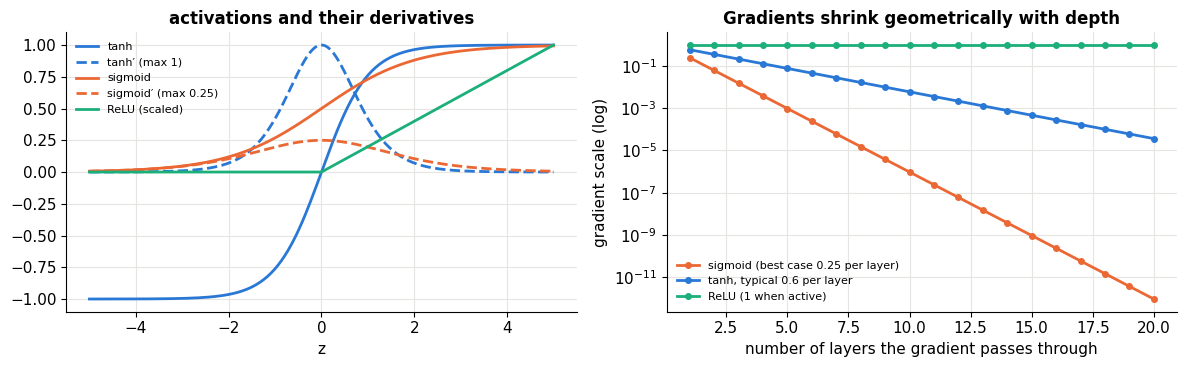

In [27]:
zz = np.linspace(-5, 5, 400)
sig = 1 / (1 + np.exp(-zz))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(zz, np.tanh(zz), color=C["blue"], label="tanh")
ax1.plot(zz, 1 - np.tanh(zz)**2, color=C["blue"], ls="--", label="tanh′ (max 1)")
ax1.plot(zz, sig, color=C["orange"], label="sigmoid")
ax1.plot(zz, sig * (1 - sig), color=C["orange"], ls="--", label="sigmoid′ (max 0.25)")
ax1.plot(zz, np.maximum(zz, 0) / 5, color=C["aqua"], label="ReLU (scaled)")
ax1.set(title="activations and their derivatives", xlabel="z"); ax1.legend(fontsize=8)

depth = np.arange(1, 21)
for name, factor, col in [("sigmoid (best case 0.25 per layer)", 0.25, C["orange"]),
                          ("tanh, typical 0.6 per layer", 0.6, C["blue"]),
                          ("ReLU (1 when active)", 1.0, C["aqua"])]:
    ax2.semilogy(depth, factor ** depth, "o-", ms=4, color=col, label=name)
ax2.set(xlabel="number of layers the gradient passes through", ylabel="gradient scale (log)",
        title="Gradients shrink geometrically with depth"); ax2.legend(fontsize=8)
fig.tight_layout(); plt.show()

This is why modern networks use **ReLU**-family activations, careful **initialization**, **normalization** layers and **residual connections** ($x + f(x)$, whose local derivative includes a "+1" that the gradient can flow through untouched). Notebooks 19, 21 and 22 deal with it in depth, and it's the reason **LSTMs** and then **transformers** replaced simple RNNs.

---
## 11. Summary

- A **derivative** measures how much the output responds to a nudge of the input. Numerically: $\frac{f(x+h) - f(x-h)}{2h}$.
- The **chain rule** multiplies local derivatives along a path and **adds** over multiple paths.
- **Backpropagation** = record the computation as a graph during the forward pass, then visit nodes in reverse topological order, each one applying its **local** derivative to the gradient flowing in.
- Two local rules cover most of it: **addition passes the gradient through**, **multiplication swaps in the other input**.
- One backward pass gives the gradient with respect to **all** parameters for roughly the cost of one forward pass. That's what makes training billion-parameter models possible.
- PyTorch's `loss.backward()` is exactly our `Value.backward()`, applied to tensors with fast kernels.
- Always **gradient-check** new code, **zero your gradients**, and watch out for **vanishing gradients** in deep chains.

### ✏️ Exercises

1. Add a `sigmoid()` operation to `Value` (forward $\sigma(x) = 1/(1+e^{-x})$, local derivative $\sigma(x)(1-\sigma(x))$). Check it against PyTorch.
2. Add a `log()` operation, then train the moons network with the **logistic loss** $\log(1 + e^{-y\cdot s})$ instead of the hinge loss.
3. In `BuggyValue`, which other operation would break if it used `=` instead of `+=`? Construct an example that shows it.
4. Extend `forward_backward` with a `tanh` hidden layer instead of ReLU. What changes in the backward pass? Verify with PyTorch.
5. Train the scalar-engine MLP on the moons with only 4 hidden units per layer. Does it still reach 100%? What does the boundary look like?
6. Without running code: in $L = (a\cdot b + c)\cdot f$, if you double $f$, which gradients change, and by how much?

### References

- Andrej Karpathy, *The spelled-out intro to neural networks and backpropagation: building micrograd* (YouTube) and the `micrograd` repository. Sections 4–7 follow this lecture closely.
- CS231n (Stanford), *Backpropagation, Intuitions* and *Derivatives, Backpropagation, and Vectorization* notes.
- CX 4240 Lecture 11 (Neural Networks: Backpropagation); ISYE 4600 W10 and HW4.
- A. Griewank & A. Walther, *Evaluating Derivatives* (the theory of automatic differentiation).

**That completes Part 0.** You now have every foundation the rest of the series uses: linear algebra (01), probability (02), optimization (03) and gradients (04).

**Next → Part 1 · [05 · Linear Regression](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/05_linear_regression.ipynb)** *(coming soon)*